# RQ3-04 — Retrain DistilBERT & RoBERTa với leakage-free training data (Đồng bộ Colab & Local)

## Protocol 80/20 (Đồng bộ cấu trúc Note 06/07 & Note 13)
- **80% Train Pool** / **20% Test** (Test được giữ độc lập, không dùng cho Early Stopping)
- **Stage A:** Chia **90% inner-train / 10% validation** bên trong 80% Train Pool để chọn `best_epoch` bằng Early Stopping
- **Stage B:** Huấn luyện trên toàn bộ **80% Train Pool** với `best_epoch`
- **Final Test & Export:** Đánh giá 1 lần trên **20% Test**, đo tốc độ Inference, vẽ Confusion Matrix, xuất bảng 18 cột và lưu `distilbert_best_final_model` & `roberta_best_final_model` cho **Notebook 13**.
- **Tương thích kép:** Tự động nhận diện **Google Colab** hoặc **Local PC**, tự động kiểm tra/đồng bộ `data_with_features_minus_1000_human.csv` từ `data_with_features.csv` mới nhất và tự động dọn checkpoint lỗi để chống đầy ổ cứng (`No space left on device`).

In [ ]:
# Ô 0: Tự động nhận diện môi trường Google Colab hoặc Local PC
import os
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    # Tự động dò tìm thư mục dự án trên Google Drive
    colab_candidates = [
        Path("/content/drive/MyDrive/project/AI-Generated-Text-Essay-Detection"),
        Path("/content/drive/MyDrive/AI-Generated-Text-Essay-Detection"),
        Path("/content/AI-Generated-Text-Essay-Detection"),
    ]
    DU_AN_PATH = next((p for p in colab_candidates if p.exists()), colab_candidates[0])
    if DU_AN_PATH.exists():
        os.chdir(DU_AN_PATH)
        if str(DU_AN_PATH) not in sys.path:
            sys.path.append(str(DU_AN_PATH))
    print(f"[Google Colab] Working directory: {Path.cwd()}")
else:
    cwd = Path.cwd()
    PROJECT_ROOT = cwd.parent if cwd.name.lower() in ["notebooks", "rq3_final_openrouter_verified"] else cwd
    if str(PROJECT_ROOT) not in sys.path:
        sys.path.append(str(PROJECT_ROOT))
    print(f"[Local PC] Working directory: {Path.cwd()} | Project root: {PROJECT_ROOT}")

Mounted at /content/drive
[Google Colab] Working directory: /content/drive/MyDrive/project/AI-Generated-Text-Essay-Detection


In [ ]:
# Nếu thiếu package:
# %pip install -U pandas numpy scikit-learn matplotlib torch transformers accelerate sentencepiece

import os
import gc
import re
import time
import shutil
import random
import hashlib
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
from torch.utils.data import Dataset, Subset

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    DataCollatorWithPadding,
    TrainingArguments,
    Trainer,
    EarlyStoppingCallback,
)

warnings.filterwarnings("ignore")

SEED = 42
TEST_SIZE = 0.20
INNER_VAL_SIZE = 0.10

# Thông số đồng bộ với Note 06/07 & phù hợp cả GPU Laptop (RTX 3050 4GB) lẫn Colab T4
MAX_LENGTH = 256
MAX_EPOCHS = 5
LEARNING_RATE = 2e-5
TRAIN_BATCH_SIZE = 4
GRAD_ACCUM_STEPS = 2   # Effective batch size = 4 * 2 = 8
EVAL_BATCH_SIZE = 16
WEIGHT_DECAY = 0.01

EARLY_STOPPING_PATIENCE = 2
EARLY_STOPPING_THRESHOLD = 1e-4

# BẮT BUỘC True ở RQ3 để xuất model cho Notebook 13 đánh giá External Benchmark
SAVE_FINAL_MODEL = True

# Chế độ tiết kiệm ổ cứng (True = tự động xóa checkpoint tạm sau khi đã lưu final model)
CLEANUP_TEMP_CHECKPOINTS = True

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(SEED)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE)
print("Torch :", torch.__version__)
if torch.cuda.is_available():
    print("GPU   :", torch.cuda.get_device_name(0))

Device: cuda
Torch : 2.11.0+cu130
GPU   : Tesla T4


## 1. Đọc & Đồng bộ `data_with_features_minus_1000_human.csv` từ data feature mới

In [ ]:
cwd = Path.cwd()
PROJECT_ROOT = cwd.parent if cwd.name.lower() in ["notebooks", "rq3_final_openrouter_verified"] else cwd

def normalize_text(text: str) -> str:
    return re.sub(r"\s+", " ", str(text).strip().lower())

def text_hash(text: str) -> str:
    return hashlib.sha256(normalize_text(text).encode("utf-8")).hexdigest()

# Tự động kiểm tra: nếu có data_with_features.csv mới + rq3_human_holdout_1000.csv thì đảm bảo file minus_1000 được cập nhật mới nhất
full_feat_candidates = [
    PROJECT_ROOT / "data" / "processed" / "data_with_features.csv",
    PROJECT_ROOT / "data_with_features.csv",
    cwd / "data_with_features.csv",
]
holdout_candidates = [
    PROJECT_ROOT / "data" / "rq3" / "rq3_human_holdout_1000.csv",
    PROJECT_ROOT / "rq3_human_holdout_1000.csv",
    cwd / "rq3_human_holdout_1000.csv",
]
minus_candidates = [
    PROJECT_ROOT / "data" / "processed" / "data_with_features_minus_1000_human.csv",
    PROJECT_ROOT / "data_with_features_minus_1000_human.csv",
    cwd / "data_with_features_minus_1000_human.csv",
    PROJECT_ROOT / "data" / "processed" / "processed_data_without_rq3_human.csv",
]

FULL_FEAT_FILE = next((p for p in full_feat_candidates if p.exists()), None)
HOLDOUT_FILE = next((p for p in holdout_candidates if p.exists()), None)
DATA_FILE = next((p for p in minus_candidates if p.exists()), None)

# Nếu có file data_with_features.csv mới và file holdout, tự động đồng bộ lại file minus_1000_human
if FULL_FEAT_FILE is not None and HOLDOUT_FILE is not None:
    df_full = pd.read_csv(FULL_FEAT_FILE)
    t_col_full = "text" if "text" in df_full.columns else "text_clean"
    df_hold = pd.read_csv(HOLDOUT_FILE)
    t_col_hold = "text_clean" if "text_clean" in df_hold.columns else "text"
    hold_hashes = set(df_hold[t_col_hold].astype(str).map(text_hash))

    need_rebuild = False
    if DATA_FILE is None or not DATA_FILE.exists():
        need_rebuild = True
    else:
        df_curr = pd.read_csv(DATA_FILE)
        # Nếu số dòng hoặc số cột chưa khớp với bản cập nhật 8 features mới (44731 - 1000 = 43731)
        if len(df_curr) != len(df_full) - len(df_hold) or "function_word_ratio" not in df_curr.columns:
            need_rebuild = True

    if need_rebuild:
        print("--> Đang tự động cập nhật data_with_features_minus_1000_human.csv từ data_with_features.csv mới...")
        df_full["_hash"] = df_full[t_col_full].astype(str).map(text_hash)
        df_synced = df_full[~df_full["_hash"].isin(hold_hashes)].drop(columns=["_hash"]).reset_index(drop=True)
        out_target = PROJECT_ROOT / "data" / "processed" / "data_with_features_minus_1000_human.csv"
        out_target.parent.mkdir(parents=True, exist_ok=True)
        df_synced.to_csv(out_target, index=False, encoding="utf-8-sig")
        DATA_FILE = out_target
        print(f"--> Đã lưu file mới tại: {DATA_FILE} (Shape: {df_synced.shape})")

if DATA_FILE is None or not DATA_FILE.exists():
    raise FileNotFoundError(
        "Không tìm thấy data_with_features_minus_1000_human.csv.\n"
        + "\n".join(f" - {p}" for p in minus_candidates)
    )

# Lưu vào đúng thư mục chuẩn mà Notebook 13 sẽ gọi
RESULT_DIR = PROJECT_ROOT / "results" / "rq3_retrain_distilbert_roberta"
RESULT_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(DATA_FILE).copy()

# Tự động đồng bộ cột 'text' nếu file dùng tên 'text_clean'
if "text" not in df.columns and "text_clean" in df.columns:
    df["text"] = df["text_clean"]

required_cols = {"text", "label"}
missing = required_cols - set(df.columns)
if missing:
    raise ValueError(f"Dataset thiếu cột: {missing}")

df = df.dropna(subset=["text", "label"]).reset_index(drop=True)
df["text"] = df["text"].astype(str)
df["label"] = df["label"].astype(int)
df["_row_id"] = np.arange(len(df))

print("DATA_FILE :", DATA_FILE)
print("RESULT_DIR:", RESULT_DIR)
print("Shape     :", df.shape)
print(df["label"].value_counts())
display(df.head())

--> Đang tự động cập nhật data_with_features_minus_1000_human.csv từ data_with_features.csv mới...
--> Đã lưu file mới tại: /content/drive/MyDrive/project/AI-Generated-Text-Essay-Detection/data/processed/data_with_features_minus_1000_human.csv (Shape: (43731, 10))
DATA_FILE : /content/drive/MyDrive/project/AI-Generated-Text-Essay-Detection/data/processed/data_with_features_minus_1000_human.csv
RESULT_DIR: /content/drive/MyDrive/project/AI-Generated-Text-Essay-Detection/results/rq3_retrain_distilbert_roberta
Shape     : (43731, 11)
label
0    26256
1    17475
Name: count, dtype: int64


,label,text,avg_word_length,punctuation_ratio,burstiness,word_count,avg_sentence_length,lexical_diversity,sentence_count,function_word_ratio,_row_id
0,0,phones modern humans today are always on their...,4.332454,0.015842,6.528088,379,13.068966,0.525066,29.0,0.364116,0
1,0,this essay will explain if drivers should or s...,4.650273,0.020319,5.129327,366,18.300000,0.469945,20.0,0.363388,1
2,0,driving while the use of cellular devices toda...,4.842697,0.012512,13.329421,178,25.428571,0.612360,7.0,0.410112,2
3,0,phones driving drivers should not be able to u...,4.786730,0.016393,3.546320,211,17.583333,0.526066,12.0,0.393365,3
4,0,cell phone operation while driving the ability...,4.722892,0.013691,9.307666,332,23.714286,0.581325,14.0,0.430723,4


## 2. Outer split: 80% Train Pool / 20% Test

In [ ]:
indices = np.arange(len(df))

train_pool_idx, test_idx = train_test_split(
    indices,
    test_size=TEST_SIZE,
    random_state=SEED,
    stratify=df["label"].values,
)

train_pool_df = df.iloc[train_pool_idx].reset_index(drop=True)
test_df = df.iloc[test_idx].reset_index(drop=True)

inner_train_idx, val_idx = train_test_split(
    np.arange(len(train_pool_df)),
    test_size=INNER_VAL_SIZE,
    random_state=SEED,
    stratify=train_pool_df["label"].values,
)

inner_train_df = train_pool_df.iloc[inner_train_idx].reset_index(drop=True)
val_df = train_pool_df.iloc[val_idx].reset_index(drop=True)

def info(name, part):
    print(
        f"{name:12s}: {len(part):6d} | "
        f"Human={(part['label']==0).sum():6d} | "
        f"AI={(part['label']==1).sum():6d} | "
        f"AI ratio={part['label'].mean():.4f}"
    )

print(f"Total        : {len(df)}")
info("Train Pool", train_pool_df)
info("  InnerTrain", inner_train_df)
info("  Validation", val_df)
info("Test", test_df)

assert set(train_pool_df["_row_id"]).isdisjoint(set(test_df["_row_id"]))
assert set(inner_train_df["_row_id"]).isdisjoint(set(val_df["_row_id"]))

manifest = pd.concat([
    train_pool_df[["_row_id", "label"]].assign(outer_split="train_80"),
    test_df[["_row_id", "label"]].assign(outer_split="test_20"),
], ignore_index=True)
manifest.to_csv(RESULT_DIR / "outer_split_manifest.csv", index=False)

print("\nSaved:", RESULT_DIR / "outer_split_manifest.csv")

Total        : 43731
Train Pool  :  34984 | Human= 21004 | AI= 13980 | AI ratio=0.3996
  InnerTrain:  31485 | Human= 18903 | AI= 12582 | AI ratio=0.3996
  Validation:   3499 | Human=  2101 | AI=  1398 | AI ratio=0.3995
Test        :   8747 | Human=  5252 | AI=  3495 | AI ratio=0.3996

Saved: /content/drive/MyDrive/project/AI-Generated-Text-Essay-Detection/results/rq3_retrain_distilbert_roberta/outer_split_manifest.csv


## 3. Dataset + Metrics

In [ ]:
class TextDataset(Dataset):
    def __init__(self, frame, tokenizer, max_length=256, return_token_type_ids=False):
        self.texts = frame["text"].tolist()
        self.labels = frame["label"].tolist()
        self.tokenizer = tokenizer
        self.max_length = max_length
        self.return_token_type_ids = return_token_type_ids

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        item = self.tokenizer(
            self.texts[idx],
            truncation=True,
            max_length=self.max_length,
            padding=False,
            return_token_type_ids=self.return_token_type_ids,
        )
        item["labels"] = int(self.labels[idx])
        return item


def softmax_np(logits):
    logits = np.asarray(logits, dtype=np.float64)
    logits = np.nan_to_num(logits, nan=0.0, posinf=1e4, neginf=-1e4)
    logits = logits - logits.max(axis=1, keepdims=True)
    exp = np.exp(logits)
    return exp / exp.sum(axis=1, keepdims=True)


def compute_metrics(eval_pred):
    logits, labels = eval_pred
    probs = softmax_np(logits)[:, 1]
    preds = np.argmax(logits, axis=1)
    return {
        "accuracy": accuracy_score(labels, preds),
        "precision": precision_score(labels, preds, zero_division=0),
        "recall": recall_score(labels, preds, zero_division=0),
        "f1": f1_score(labels, preds, zero_division=0),
        "roc_auc": roc_auc_score(labels, probs),
    }


def final_metrics(labels, logits):
    probs = softmax_np(logits)[:, 1]
    preds = np.argmax(logits, axis=1)
    metrics = {
        "Accuracy": accuracy_score(labels, preds),
        "Precision": precision_score(labels, preds, zero_division=0),
        "Recall": recall_score(labels, preds, zero_division=0),
        "F1": f1_score(labels, preds, zero_division=0),
        "ROC-AUC": roc_auc_score(labels, probs),
    }
    return metrics, preds, probs

## 4. Train 2 giai đoạn (Stage A & Stage B — Tự động lọc checkpoint hỏng & Tiết kiệm ổ cứng)

In [ ]:
def get_valid_checkpoints(stage_dir: Path):
    """Kiểm tra và xóa tự động các checkpoint bị ghi dở (corrupted) do hết ổ cứng trước đó."""
    if not stage_dir.exists():
        return []
    valid_ckpts = []
    for ckpt in sorted(stage_dir.glob("checkpoint-*"), key=os.path.getmtime):
        state_file = ckpt / "trainer_state.json"
        safetensor_file = ckpt / "model.safetensors"
        bin_file = ckpt / "pytorch_model.bin"
        has_weights = (safetensor_file.exists() and safetensor_file.stat().st_size > 10_000_000) or (
            bin_file.exists() and bin_file.stat().st_size > 10_000_000
        )
        if state_file.exists() and has_weights:
            valid_ckpts.append(ckpt)
        else:
            print(f"⚠️ Phát hiện checkpoint bị hỏng/ghi dở: {ckpt.name} -> Đang xóa tự động...")
            shutil.rmtree(ckpt, ignore_errors=True)
    return valid_ckpts


def run_model(model_name, short_name, force_fp32=False):
    print("\n" + "="*90)
    print(f"{short_name}: STAGE A — EARLY STOPPING")
    print("="*90)

    total, used, free = shutil.disk_usage(RESULT_DIR)
    print(f"Dung lượng ổ đĩa còn trống: {free / (1024**3):.2f} GB")

    set_seed(SEED)
    tokenizer = AutoTokenizer.from_pretrained(model_name)
    collator = DataCollatorWithPadding(tokenizer=tokenizer)

    use_fp16 = False if force_fp32 else torch.cuda.is_available()
    model_kwargs = {"num_labels": 2, "ignore_mismatched_sizes": True}
    if force_fp32:
        model_kwargs["torch_dtype"] = torch.float32

    inner_train_ds = TextDataset(inner_train_df, tokenizer, MAX_LENGTH)
    val_ds = TextDataset(val_df, tokenizer, MAX_LENGTH)

    stage_a_dir = RESULT_DIR / f"{short_name.lower()}_stage_a"
    valid_ckpts_a = get_valid_checkpoints(stage_a_dir)

    resume_ckpt_a = None
    if len(valid_ckpts_a) > 0:
        latest_ckpt_a = valid_ckpts_a[-1]
        # Kiểm tra xem optimizer.pt có tồn tại để Trainer.train(resume_from_checkpoint=...) không
        if (latest_ckpt_a / "optimizer.pt").exists():
            resume_ckpt_a = str(latest_ckpt_a)
            print(f"Tìm thấy checkpoint Stage A hợp lệ: {latest_ckpt_a.name}, sẽ tiếp tục huấn luyện...")
            stage_a_model = AutoModelForSequenceClassification.from_pretrained(latest_ckpt_a, **model_kwargs)
        else:
            print(f"Nạp trọng số từ checkpoint Stage A: {latest_ckpt_a.name}")
            stage_a_model = AutoModelForSequenceClassification.from_pretrained(latest_ckpt_a, **model_kwargs)
    else:
        print("Khởi tạo mô hình Stage A từ pretrained gốc:", model_name)
        stage_a_model = AutoModelForSequenceClassification.from_pretrained(model_name, **model_kwargs)

    stage_a_args = TrainingArguments(
        output_dir=str(stage_a_dir),
        eval_strategy="epoch",
        save_strategy="epoch",
        save_only_model=True,   # Không lưu optimizer.pt (~1GB) để tránh lỗi No space left on device
        save_total_limit=1,     # Chỉ giữ tối đa 1 checkpoint tốt nhất trên đĩa
        logging_strategy="steps",
        logging_steps=100,

        learning_rate=LEARNING_RATE,
        per_device_train_batch_size=TRAIN_BATCH_SIZE,
        gradient_accumulation_steps=GRAD_ACCUM_STEPS,
        per_device_eval_batch_size=EVAL_BATCH_SIZE,
        num_train_epochs=MAX_EPOCHS,
        weight_decay=WEIGHT_DECAY,
        max_grad_norm=1.0,

        load_best_model_at_end=True,
        metric_for_best_model="f1",
        greater_is_better=True,

        seed=SEED,
        data_seed=SEED,
        report_to="none",

        fp16=use_fp16,
        bf16=False,
        dataloader_num_workers=0,
    )

    stage_a_trainer = Trainer(
        model=stage_a_model,
        args=stage_a_args,
        train_dataset=inner_train_ds,
        eval_dataset=val_ds,
        data_collator=collator,
        compute_metrics=compute_metrics,
        callbacks=[
            EarlyStoppingCallback(
                early_stopping_patience=EARLY_STOPPING_PATIENCE,
                early_stopping_threshold=EARLY_STOPPING_THRESHOLD,
            )
        ],
    )

    stage_a_output = stage_a_trainer.train(resume_from_checkpoint=resume_ckpt_a)
    stage_a_seconds = float(stage_a_output.metrics["train_runtime"])

    best_val_f1 = stage_a_trainer.state.best_metric
    best_ckpt = stage_a_trainer.state.best_model_checkpoint

    eval_rows = [
        x for x in stage_a_trainer.state.log_history
        if "eval_f1" in x and "epoch" in x
    ]
    if not eval_rows:
        raise RuntimeError("Không lấy được epoch validation từ training history.")

    best_row = max(eval_rows, key=lambda x: x["eval_f1"])
    best_epoch_float = float(best_row["epoch"])
    best_epoch = max(1, int(round(best_epoch_float)))

    print("\nBest checkpoint Stage A:", best_ckpt)
    print("Best Val F1 Stage A   :", best_val_f1)
    print("Best epoch Stage A    :", best_epoch)

    hist = pd.DataFrame(stage_a_trainer.state.log_history)
    hist.to_csv(
        RESULT_DIR / f"{short_name.lower()}_stage_a_history.csv",
        index=False
    )

    del stage_a_trainer, stage_a_model, inner_train_ds, val_ds
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    # ---------------------------------------------------------
    # STAGE B: RETRAIN TRÊN TOÀN BỘ 80% TRAIN POOL
    # ---------------------------------------------------------
    print("\n" + "="*90)
    print(f"{short_name}: STAGE B — RETRAIN FULL 80% TRAIN POOL FOR {best_epoch} EPOCH(S)")
    print("="*90)

    set_seed(SEED)

    full_train_ds = TextDataset(train_pool_df, tokenizer, MAX_LENGTH)
    test_ds = TextDataset(test_df, tokenizer, MAX_LENGTH)

    final_dir = RESULT_DIR / f"{short_name.lower()}_final_80"
    shutil.rmtree(final_dir, ignore_errors=True)

    init_source = best_ckpt if (best_ckpt and Path(best_ckpt).exists()) else model_name
    print("Khởi tạo Stage B từ:", init_source)
    final_model = AutoModelForSequenceClassification.from_pretrained(
        init_source, **model_kwargs
    )

    # Xóa ngay thư mục tạm Stage A sau khi đã load model vào RAM để giải phóng dung lượng ổ cứng
    if CLEANUP_TEMP_CHECKPOINTS:
        shutil.rmtree(stage_a_dir, ignore_errors=True)

    final_args = TrainingArguments(
        output_dir=str(final_dir),
        eval_strategy="no",
        save_strategy="no",     # Không lưu checkpoint trung gian ở Stage B để bảo vệ ổ cứng
        logging_strategy="steps",
        logging_steps=100,

        learning_rate=LEARNING_RATE,
        per_device_train_batch_size=TRAIN_BATCH_SIZE,
        gradient_accumulation_steps=GRAD_ACCUM_STEPS,
        per_device_eval_batch_size=EVAL_BATCH_SIZE,
        num_train_epochs=best_epoch,
        weight_decay=WEIGHT_DECAY,
        max_grad_norm=1.0,

        seed=SEED,
        data_seed=SEED,
        report_to="none",

        fp16=use_fp16,
        bf16=False,
        dataloader_num_workers=0,
    )

    final_trainer = Trainer(
        model=final_model,
        args=final_args,
        train_dataset=full_train_ds,
        data_collator=collator,
    )

    stage_b_output = final_trainer.train()
    stage_b_seconds = float(stage_b_output.metrics["train_runtime"])
    print(f"Stage A: {stage_a_seconds:.2f}s | Stage B: {stage_b_seconds:.2f}s | Total A+B: {stage_a_seconds + stage_b_seconds:.2f}s")

    print(f"\nFINAL TEST — {short_name}")

    # Warmup để loại bỏ overhead khởi tạo kernel
    warmup_size = min(EVAL_BATCH_SIZE * 2, len(test_ds))
    _ = final_trainer.predict(Subset(test_ds, range(warmup_size)))

    # Đo thời gian suy luận trên toàn bộ Test 20%
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    t_infer_start = time.perf_counter()
    test_out = final_trainer.predict(test_ds)
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    infer_seconds = time.perf_counter() - t_infer_start
    n_test = len(test_ds)
    infer_ms_per_sample = infer_seconds / n_test * 1000
    infer_samples_per_sec = n_test / infer_seconds if infer_seconds > 0 else float("inf")
    print(f"Inference: {infer_seconds:.2f}s total | {infer_ms_per_sample:.3f} ms/sample | {infer_samples_per_sec:.1f} samples/s")

    m, y_pred, y_prob = final_metrics(
        test_out.label_ids,
        test_out.predictions
    )

    # Confusion Matrix
    y_true = test_out.label_ids
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()
    print(f"Confusion Matrix: TN={tn} | FP={fp} | FN={fn} | TP={tp}")

    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Human (0)", "AI (1)"])
    fig_cm, ax_cm = plt.subplots(figsize=(5.5, 4.5))
    disp.plot(ax=ax_cm, cmap="Blues", values_format="d", colorbar=True)
    ax_cm.set_title(f"Confusion Matrix — {short_name} (Test 20%, n={n_test})")
    cm_path = RESULT_DIR / f"{short_name.lower()}_confusion_matrix.png"
    plt.savefig(cm_path, dpi=200, bbox_inches="tight")
    plt.show()
    print("Saved:", cm_path)

    result = {
        "Model": short_name,
        "Pretrained": model_name,
        "Stage_A_seconds": stage_a_seconds,
        "Stage_B_seconds": stage_b_seconds,
        "Total_AB_seconds": stage_a_seconds + stage_b_seconds,
        "Infer_total_seconds": infer_seconds,
        "Infer_ms_per_sample": infer_ms_per_sample,
        "Infer_samples_per_sec": infer_samples_per_sec,
        "TN": int(tn),
        "FP": fp,
        "FN": fn,
        "TP": tp,
        **m,
        "Best_val_F1_stage_A": best_val_f1,
        "Selected_epoch": best_epoch,
        "Outer_train_ratio": 0.80,
        "Outer_test_ratio": 0.20,
        "LR": LEARNING_RATE,
        "Train_batch": TRAIN_BATCH_SIZE,
        "Effective_batch": TRAIN_BATCH_SIZE * GRAD_ACCUM_STEPS,
        "Eval_batch": EVAL_BATCH_SIZE,
        "Max_length": MAX_LENGTH,
    }

    pred_df = pd.DataFrame({
        "_row_id": test_df["_row_id"].values,
        "label": test_out.label_ids,
        "prediction": y_pred,
        "prob_ai": y_prob,
        "text": test_df["text"].values,
    })
    pred_df.to_csv(
        RESULT_DIR / f"{short_name.lower()}_test_predictions.csv",
        index=False
    )

    print()
    for k in ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]:
        print(f"{k:10s}: {m[k]:.6f}")

    if SAVE_FINAL_MODEL:
        save_dir = RESULT_DIR / f"{short_name.lower()}_best_final_model"
        shutil.rmtree(save_dir, ignore_errors=True)
        final_trainer.save_model(str(save_dir))
        tokenizer.save_pretrained(str(save_dir))
        print("Saved final model for Notebook 13:", save_dir)

    if CLEANUP_TEMP_CHECKPOINTS:
        shutil.rmtree(final_dir, ignore_errors=True)

    del final_trainer, final_model, full_train_ds, test_ds
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return result

## 5. DistilBERT


DistilBERT: STAGE A — EARLY STOPPING
Dung lượng ổ đĩa còn trống: 106.67 GB


config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Khởi tạo mô hình Stage A từ pretrained gốc: distilbert-base-uncased


... (9 outputs left out)

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Step,Training Loss
100,0.102438
200,0.101243
300,0.178262
400,0.094042
500,0.110018
600,0.057102
700,0.014340
800,0.024016
900,0.074890
1000,0.122800


Stage A: 1072.25s | Stage B: 369.48s | Total A+B: 1441.73s

FINAL TEST — DistilBERT


Inference: 28.57s total | 3.266 ms/sample | 306.2 samples/s
Confusion Matrix: TN=5216 | FP=36 | FN=10 | TP=3485


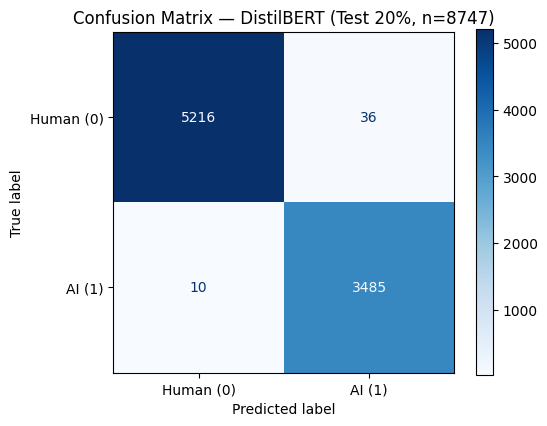

Saved: /content/drive/MyDrive/project/AI-Generated-Text-Essay-Detection/results/rq3_retrain_distilbert_roberta/distilbert_confusion_matrix.png

Accuracy  : 0.994741
Precision : 0.989776
Recall    : 0.997139
F1        : 0.993444
ROC-AUC   : 0.999894


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Saved final model for Notebook 13: /content/drive/MyDrive/project/AI-Generated-Text-Essay-Detection/results/rq3_retrain_distilbert_roberta/distilbert_best_final_model


In [ ]:
distil_result = run_model(
    "distilbert-base-uncased",
    "DistilBERT",
    force_fp32=False,
)

## 6. RoBERTa


RoBERTa: STAGE A — EARLY STOPPING
Dung lượng ổ đĩa còn trống: 106.17 GB


config.json:   0%|          | 0.00/481 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

... (12 outputs left out)

Step,Training Loss
100,0.061972
200,0.079710
300,0.070335
400,0.191367
500,0.056480
600,0.027047
700,0.056169
800,0.071514
900,0.140786
1000,0.086295


Step,Training Loss
100,0.061972
200,0.079710
300,0.070335
400,0.191367
500,0.056480
600,0.027047
700,0.056169
800,0.071514
900,0.140786
1000,0.086295


Stage A: 2425.77s | Stage B: 1274.71s | Total A+B: 3700.48s

FINAL TEST — RoBERTa


Inference: 39.76s total | 4.545 ms/sample | 220.0 samples/s
Confusion Matrix: TN=5195 | FP=57 | FN=5 | TP=3490


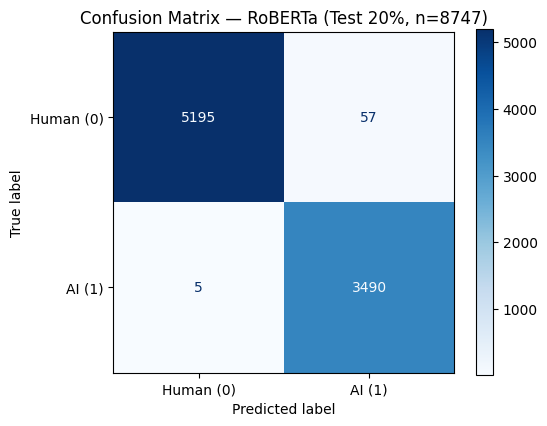

Saved: /content/drive/MyDrive/project/AI-Generated-Text-Essay-Detection/results/rq3_retrain_distilbert_roberta/roberta_confusion_matrix.png

Accuracy  : 0.992912
Precision : 0.983930
Recall    : 0.998569
F1        : 0.991196
ROC-AUC   : 0.999903


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Saved final model for Notebook 13: /content/drive/MyDrive/project/AI-Generated-Text-Essay-Detection/results/rq3_retrain_distilbert_roberta/roberta_best_final_model


In [ ]:
roberta_result = run_model(
    "roberta-base",
    "RoBERTa",
    force_fp32=False,
)

## 7. Final comparison

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,Best_val_F1_stage_A,Selected_epoch,Stage_A_seconds,Stage_B_seconds,Total_AB_seconds,Infer_total_seconds,Infer_ms_per_sample,Infer_samples_per_sec,TN,FP,FN,TP
0,DistilBERT,0.994741,0.989776,0.997139,0.993444,0.999894,0.992081,1,1072.2517,369.4799,1441.7316,28.567797,3.266011,306.183912,5216,36,10,3485
1,RoBERTa,0.992912,0.983930,0.998569,0.991196,0.999903,0.996413,2,2425.7725,1274.7061,3700.4786,39.755766,4.545074,220.018398,5195,57,5,3490


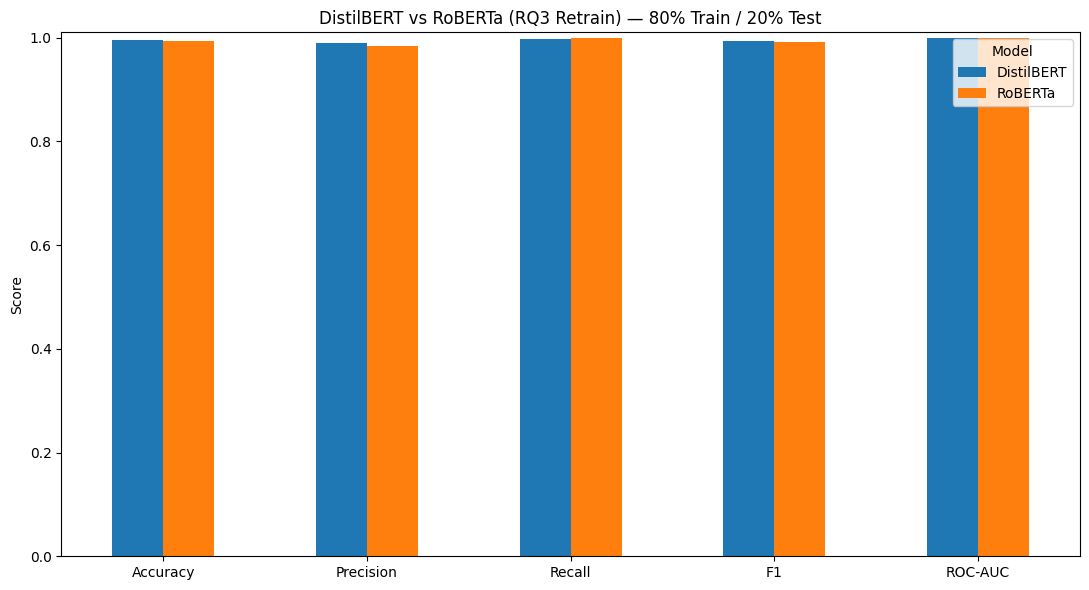

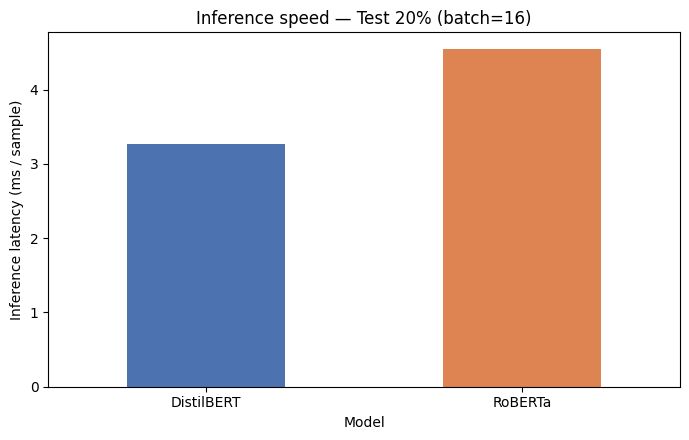

Saved: /content/drive/MyDrive/project/AI-Generated-Text-Essay-Detection/results/rq3_retrain_distilbert_roberta/distilbert_roberta_internal_results.csv
Saved: /content/drive/MyDrive/project/AI-Generated-Text-Essay-Detection/results/rq3_retrain_distilbert_roberta/distilbert_roberta_80_20_results.csv
Saved: /content/drive/MyDrive/project/AI-Generated-Text-Essay-Detection/results/rq3_retrain_distilbert_roberta/distilbert_roberta_80_20_metrics.png


In [ ]:
results_df = pd.DataFrame([distil_result, roberta_result])

display(
    results_df[
        [
            "Model",
            "Accuracy",
            "Precision",
            "Recall",
            "F1",
            "ROC-AUC",
            "Best_val_F1_stage_A",
            "Selected_epoch",
            "Stage_A_seconds",
            "Stage_B_seconds",
            "Total_AB_seconds",
            "Infer_total_seconds",
            "Infer_ms_per_sample",
            "Infer_samples_per_sec",
            "TN",
            "FP",
            "FN",
            "TP",
        ]
    ].sort_values("F1", ascending=False)
)

# Lưu cả 2 tên file CSV để tương thích với cả Notebook 13 lẫn cấu trúc báo cáo RQ2/RQ3
summary_path_internal = RESULT_DIR / "distilbert_roberta_internal_results.csv"
summary_path_80_20 = RESULT_DIR / "distilbert_roberta_80_20_results.csv"
results_df.to_csv(summary_path_internal, index=False)
results_df.to_csv(summary_path_80_20, index=False)

plot_df = results_df.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]
]
ax = plot_df.T.plot(kind="bar", figsize=(11, 6))
ax.set_ylim(0, 1.01)
ax.set_ylabel("Score")
ax.set_title("DistilBERT vs RoBERTa (RQ3 Retrain) — 80% Train / 20% Test")
plt.xticks(rotation=0)
plt.tight_layout()

fig_path = RESULT_DIR / "distilbert_roberta_80_20_metrics.png"
plt.savefig(fig_path, dpi=200, bbox_inches="tight")
plt.show()

fig_inf, ax_inf = plt.subplots(figsize=(7, 4.5))
results_df.set_index("Model")["Infer_ms_per_sample"].plot(kind="bar", ax=ax_inf, color=["#4C72B0", "#DD8452"])
ax_inf.set_ylabel("Inference latency (ms / sample)")
ax_inf.set_title(f"Inference speed — Test 20% (batch={EVAL_BATCH_SIZE})")
plt.xticks(rotation=0)
plt.tight_layout()
inf_fig_path = RESULT_DIR / "distilbert_roberta_inference_time.png"
plt.savefig(inf_fig_path, dpi=200, bbox_inches="tight")
plt.show()

print("Saved:", summary_path_internal)
print("Saved:", summary_path_80_20)
print("Saved:", fig_path)

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive
